# Bellabeat Smart Device Usage Analysis

## Introduction

This case study explores smart-device usage patterns using Fitbit fitness tracker data to identify potential opportunities for Bellabeat, a health-focused technology company.

The analysis examines daily steps, activity patterns across the week, and recorded sleep duration. The goal is to develop data-informed recommendations that Bellabeat could explore to improve user engagement and guide its marketing strategy.

## Business Task

Identify trends in smart-device usage and explain how these trends could inform Bellabeat's product engagement and marketing decisions.

## Business Questions

1. What trends can be identified in smart-device usage?
2. How might these trends apply to Bellabeat customers?
3. How could these trends influence Bellabeat's marketing strategy?

## Tools Used

- Python
- pandas for data cleaning and analysis
- Matplotlib for data visualization
- Google Colab for notebook development

In [1]:
# Fitbit data is already extracted in Google Colab
import os

print("Fitbit data folder exists:",
      os.path.exists("/content/fitbit_data"))

Fitbit data folder exists: True


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt


daily_file = (
    "/content/fitbit_data/"
    "mturkfitbit_export_3.12.16-4.11.16/"
    "Fitabase Data 3.12.16-4.11.16/"
    "dailyActivity_merged.csv"
)


sleep_file = (
    "/content/fitbit_data/"
    "mturkfitbit_export_4.12.16-5.12.16/"
    "Fitabase Data 4.12.16-5.12.16/"
    "sleepDay_merged.csv"
)

print("Daily activity file exists:", os.path.exists(daily_file))
print("Sleep file exists:", os.path.exists(sleep_file))

Daily activity file exists: True
Sleep file exists: True


In [3]:

# Load the correct activity and sleep datasets

daily_activity = pd.read_csv(daily_file)
sleep_day = pd.read_csv(sleep_file)

print("Daily activity rows and columns:", daily_activity.shape)
print("Sleep rows and columns:", sleep_day.shape)


Daily activity rows and columns: (457, 15)
Sleep rows and columns: (413, 5)


In [4]:

# Clean duplicate sleep records and format dates

sleep_day = sleep_day.drop_duplicates().copy()

daily_activity["ActivityDate"] = pd.to_datetime(
    daily_activity["ActivityDate"],
    format="%m/%d/%Y"
)

sleep_day["SleepDay"] = pd.to_datetime(
    sleep_day["SleepDay"],
    format="%m/%d/%Y %I:%M:%S %p"
)

sleep_day["HoursAsleep"] = sleep_day["TotalMinutesAsleep"] / 60
sleep_day["HoursInBed"] = sleep_day["TotalTimeInBed"] / 60

print("Daily activity rows:", len(daily_activity))
print("Sleep rows after removing duplicates:", len(sleep_day))
print("Remaining duplicate sleep rows:", sleep_day.duplicated().sum())


Daily activity rows: 457
Sleep rows after removing duplicates: 410
Remaining duplicate sleep rows: 0


In [5]:

# Restore columns needed for analysis

daily_activity["DayOfWeek"] = (
    daily_activity["ActivityDate"].dt.day_name()
)

daily_activity["Date"] = daily_activity["ActivityDate"].dt.date
sleep_day["Date"] = sleep_day["SleepDay"].dt.date

def classify_activity(steps):
    if steps < 5000:
        return "Low"
    elif steps < 7500:
        return "Moderate"
    else:
        return "High"

daily_activity["ActivityLevel"] = (
    daily_activity["TotalSteps"].apply(classify_activity)
)

print("Analysis columns restored successfully!")
print(
    daily_activity[
        ["ActivityDate", "DayOfWeek", "TotalSteps", "ActivityLevel"]
    ].head()
)


Analysis columns restored successfully!
  ActivityDate DayOfWeek  TotalSteps ActivityLevel
0   2016-03-25    Friday       11004          High
1   2016-03-26  Saturday       17609          High
2   2016-03-27    Sunday       12736          High
3   2016-03-28    Monday       13231          High
4   2016-03-29   Tuesday       12041          High


In [6]:
import pandas as pd
import os
import matplotlib.pyplot as plt
daily_activity = pd.read_csv(daily_file)

In [7]:
daily_activity = pd.read_csv(daily_file)
sleep_day = pd.read_csv(sleep_file)

print("Daily activity shape:", daily_activity.shape)
print("Sleep data shape:", sleep_day.shape)

Daily activity shape: (457, 15)
Sleep data shape: (413, 5)


In [8]:
print("Daily activity rows:", len(daily_activity))
print("Sleep rows:", len(sleep_day))

print("\nDaily activity columns:")
print(daily_activity.columns.tolist())

print("\nSleep columns:")
print(sleep_day.columns.tolist())

Daily activity rows: 457
Sleep rows: 413

Daily activity columns:
['Id', 'ActivityDate', 'TotalSteps', 'TotalDistance', 'TrackerDistance', 'LoggedActivitiesDistance', 'VeryActiveDistance', 'ModeratelyActiveDistance', 'LightActiveDistance', 'SedentaryActiveDistance', 'VeryActiveMinutes', 'FairlyActiveMinutes', 'LightlyActiveMinutes', 'SedentaryMinutes', 'Calories']

Sleep columns:
['Id', 'SleepDay', 'TotalSleepRecords', 'TotalMinutesAsleep', 'TotalTimeInBed']


In [9]:
import pandas as pd

file1 = (
    "/content/fitbit_data/"
    "mturkfitbit_export_4.12.16-5.12.16/"
    "Fitabase Data 4.12.16-5.12.16/"
    "dailyActivity_merged.csv"
)

file2 = (
    "/content/fitbit_data/"
    "mturkfitbit_export_3.12.16-4.11.16/"
    "Fitabase Data 3.12.16-4.11.16/"
    "dailyActivity_merged.csv"
)

activity1 = pd.read_csv(file1)
activity2 = pd.read_csv(file2)

print("File 1 rows:", len(activity1))
print("File 2 rows:", len(activity2))
print("File 1 date range:", activity1["ActivityDate"].min(),
      "to", activity1["ActivityDate"].max())
print("File 2 date range:", activity2["ActivityDate"].min(),
      "to", activity2["ActivityDate"].max())

File 1 rows: 940
File 2 rows: 457
File 1 date range: 4/12/2016 to 5/9/2016
File 2 date range: 3/12/2016 to 4/9/2016


In [10]:
daily_activity = activity2.copy()
sleep_day = pd.read_csv(sleep_file)

print("Daily activity rows:", len(daily_activity))
print("Sleep rows:", len(sleep_day))

Daily activity rows: 457
Sleep rows: 413


In [11]:
# Remove duplicate sleep records
sleep_day = sleep_day.drop_duplicates().copy()

# Convert date columns
daily_activity["ActivityDate"] = pd.to_datetime(
    daily_activity["ActivityDate"],
    format="%m/%d/%Y"
)

sleep_day["SleepDay"] = pd.to_datetime(
    sleep_day["SleepDay"],
    format="%m/%d/%Y %I:%M:%S %p"
)

# Re-create sleep duration columns
sleep_day["HoursAsleep"] = sleep_day["TotalMinutesAsleep"] / 60
sleep_day["HoursInBed"] = sleep_day["TotalTimeInBed"] / 60

print("Daily activity rows:", len(daily_activity))
print("Sleep rows after removing duplicates:", len(sleep_day))
print("Duplicate sleep rows remaining:", sleep_day.duplicated().sum())

Daily activity rows: 457
Sleep rows after removing duplicates: 410
Duplicate sleep rows remaining: 0


In [12]:
# Re-create the day-of-week column
daily_activity["DayOfWeek"] = (
    daily_activity["ActivityDate"].dt.day_name()
)

# Re-create the date columns used to compare activity and sleep
daily_activity["Date"] = daily_activity["ActivityDate"].dt.date
sleep_day["Date"] = sleep_day["SleepDay"].dt.date

# Re-create activity level categories
def classify_activity(steps):
    if steps < 5000:
        return "Low"
    elif steps < 7500:
        return "Moderate"
    else:
        return "High"

daily_activity["ActivityLevel"] = (
    daily_activity["TotalSteps"].apply(classify_activity)
)

print("Analysis columns restored successfully!")
print(daily_activity[
    ["ActivityDate", "DayOfWeek", "TotalSteps", "ActivityLevel"]
].head())

Analysis columns restored successfully!
  ActivityDate DayOfWeek  TotalSteps ActivityLevel
0   2016-03-25    Friday       11004          High
1   2016-03-26  Saturday       17609          High
2   2016-03-27    Sunday       12736          High
3   2016-03-28    Monday       13231          High
4   2016-03-29   Tuesday       12041          High


In [13]:

# Restore the main activity summary statistics

print("Number of daily records:", len(daily_activity))
print("Number of unique users:", daily_activity["Id"].nunique())
print("Average daily steps:", round(daily_activity["TotalSteps"].mean(), 2))
print("Median daily steps:", daily_activity["TotalSteps"].median())
print("Minimum daily steps:", daily_activity["TotalSteps"].min())
print("Maximum daily steps:", daily_activity["TotalSteps"].max())
print("Average daily calories:", round(daily_activity["Calories"].mean(), 2))
print("Average sedentary minutes:", round(daily_activity["SedentaryMinutes"].mean(), 2))


Number of daily records: 457
Number of unique users: 35
Average daily steps: 6546.56
Median daily steps: 5986.0
Minimum daily steps: 0
Maximum daily steps: 28497
Average daily calories: 2189.45
Average sedentary minutes: 995.28


In [14]:

# Restore sleep summary statistics

print("Sleep records:", len(sleep_day))
print("Unique users with sleep records:", sleep_day["Id"].nunique())
print("Average sleep (hours):", round(sleep_day["HoursAsleep"].mean(), 2))
print("Average time in bed (hours):", round(sleep_day["HoursInBed"].mean(), 2))

difference = sleep_day["HoursInBed"].mean() - sleep_day["HoursAsleep"].mean()
print("Average difference (hours):", round(difference, 2))


Sleep records: 410
Unique users with sleep records: 24
Average sleep (hours): 6.99
Average time in bed (hours): 7.64
Average difference (hours): 0.66


In [15]:

# Average daily steps by day of the week

weekday_steps = daily_activity.groupby("DayOfWeek")["TotalSteps"].mean()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_steps = weekday_steps.reindex(weekday_order)

print("Average steps by weekday:")
print(weekday_steps.round(0))


Average steps by weekday:
DayOfWeek
Monday       7119.0
Tuesday      4915.0
Wednesday    7511.0
Thursday     6847.0
Friday       6738.0
Saturday     7090.0
Sunday       6058.0
Name: TotalSteps, dtype: float64


In [16]:

# Count daily records by activity level

activity_counts = daily_activity["ActivityLevel"].value_counts()

activity_order = ["Low", "Moderate", "High"]
activity_counts = activity_counts.reindex(activity_order, fill_value=0)

activity_percentages = (
    activity_counts / len(daily_activity) * 100
)

print("Daily records by activity level:")
print(activity_counts)

print("\nPercentage by activity level:")
print(activity_percentages.round(1))


Daily records by activity level:
ActivityLevel
Low         197
Moderate     83
High        177
Name: count, dtype: int64

Percentage by activity level:
ActivityLevel
Low         43.1
Moderate    18.2
High        38.7
Name: count, dtype: float64


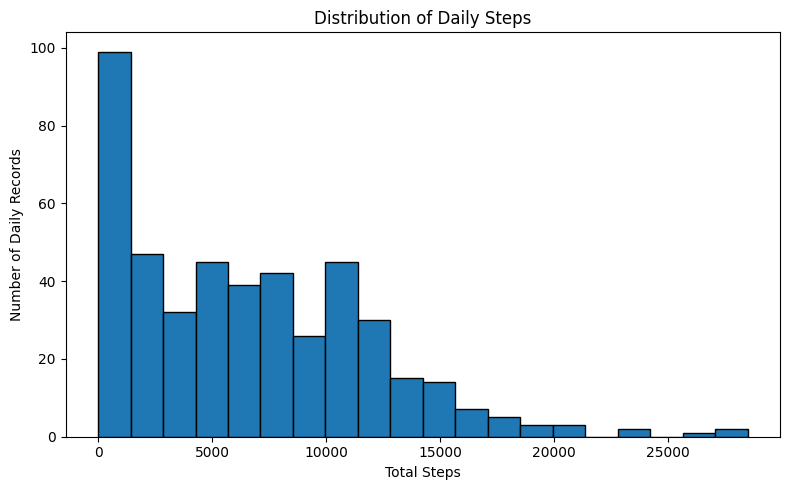

In [17]:

# Chart 1: Distribution of daily steps

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(daily_activity["TotalSteps"], bins=20, edgecolor="black")

plt.title("Distribution of Daily Steps")
plt.xlabel("Total Steps")
plt.ylabel("Number of Daily Records")

plt.tight_layout()
plt.savefig("bellabeat_daily_steps_distribution.png", dpi=300)
plt.show()


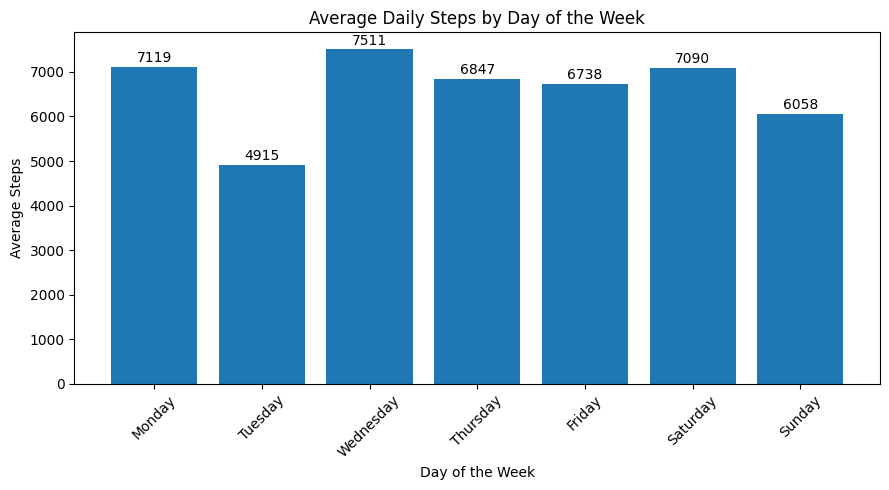

In [18]:

# Chart 2: Average daily steps by weekday

plt.figure(figsize=(9, 5))

bars = plt.bar(weekday_steps.index, weekday_steps.values)

plt.title("Average Daily Steps by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Steps")
plt.xticks(rotation=45)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f"{bar.get_height():.0f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig("bellabeat_steps_by_weekday.png", dpi=300)
plt.show()


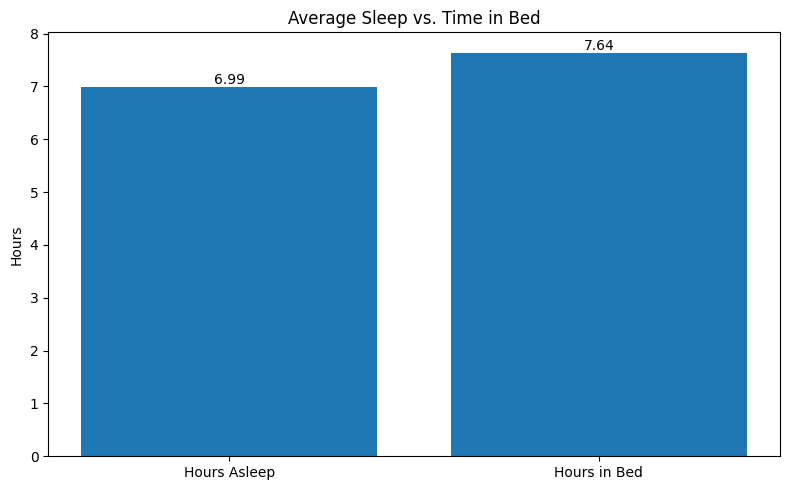

In [19]:

# Chart 3: Average sleep vs. time in bed

sleep_averages = [
    sleep_day["HoursAsleep"].mean(),
    sleep_day["HoursInBed"].mean()
]

labels = ["Hours Asleep", "Hours in Bed"]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, sleep_averages)

plt.title("Average Sleep vs. Time in Bed")
plt.ylabel("Hours")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f"{bar.get_height():.2f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig("bellabeat_sleep_vs_time_in_bed.png", dpi=300)
plt.show()


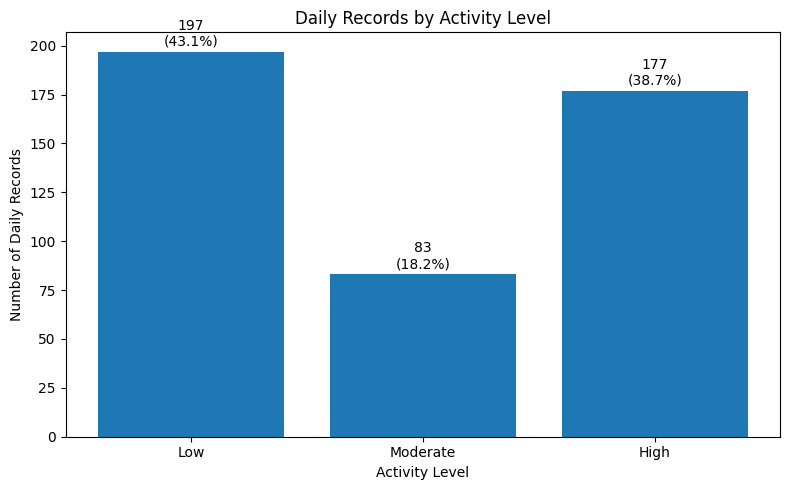

In [20]:

# Chart 4: Daily records by activity level

activity_order = ["Low", "Moderate", "High"]

activity_counts_ordered = (
    daily_activity["ActivityLevel"]
    .value_counts()
    .reindex(activity_order, fill_value=0)
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    activity_counts_ordered.index,
    activity_counts_ordered.values
)

plt.title("Daily Records by Activity Level")
plt.xlabel("Activity Level")
plt.ylabel("Number of Daily Records")

for bar, count in zip(bars, activity_counts_ordered.values):
    percentage = count / len(daily_activity) * 100
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 3,
        f"{count}\n({percentage:.1f}%)",
        ha="center"
    )

plt.tight_layout()
plt.savefig("bellabeat_activity_levels.png", dpi=300)
plt.show()


In [21]:

# Verify that all four charts were saved

import os

chart_files = [
    "bellabeat_daily_steps_distribution.png",
    "bellabeat_steps_by_weekday.png",
    "bellabeat_sleep_vs_time_in_bed.png",
    "bellabeat_activity_levels.png"
]

for filename in chart_files:
    print(filename, "—", "Saved" if os.path.exists(filename) else "MISSING")


bellabeat_daily_steps_distribution.png — Saved
bellabeat_steps_by_weekday.png — Saved
bellabeat_sleep_vs_time_in_bed.png — Saved
bellabeat_activity_levels.png — Saved


In [22]:
import os

print(os.listdir('/content'))

['.config', 'fitbit_data', 'bellabeat_daily_steps_distribution.png', 'bellabeat_steps_by_weekday.png', 'archive (3).zip', 'bellabeat_sleep_vs_time_in_bed.png', 'bellabeat_activity_levels.png', 'sample_data']


In [23]:
import os

print(os.listdir('/content/fitbit_data'))

['mturkfitbit_export_4.12.16-5.12.16', 'mturkfitbit_export_3.12.16-4.11.16']


In [24]:
import os

for root, dirs, files in os.walk('/content/fitbit_data'):
    for file in files:
        if file in ['dailyActivity_merged.csv', 'sleepDay_merged.csv']:
            print(os.path.join(root, file))

/content/fitbit_data/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/sleepDay_merged.csv
/content/fitbit_data/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/dailyActivity_merged.csv
/content/fitbit_data/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/dailyActivity_merged.csv


In [25]:
#Next exact action: Extract the ZIP file
import zipfile
import os

with zipfile.ZipFile('/content/archive (3).zip', 'r') as zip_ref:
    zip_ref.extractall('/content/fitbit_data')

print(os.listdir('/content/fitbit_data'))

['mturkfitbit_export_4.12.16-5.12.16', 'mturkfitbit_export_3.12.16-4.11.16']


In [26]:
import os

base_path = "/content/fitbit_data"

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

/content/fitbit_data/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/minuteCaloriesNarrow_merged.csv
/content/fitbit_data/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/hourlySteps_merged.csv
/content/fitbit_data/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/dailySteps_merged.csv
/content/fitbit_data/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/minuteStepsWide_merged.csv
/content/fitbit_data/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/weightLogInfo_merged.csv
/content/fitbit_data/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/minuteIntensitiesWide_merged.csv
/content/fitbit_data/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/minuteStepsNarrow_merged.csv
/content/fitbit_data/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/sleepDay_merged.csv
/content/fitbit_data/mturkfitbit_export_4.12.16-5.12.16/Fitabase Data 4.12.16-5.12.16/dailyIntensitie

In [27]:

#Next exact action: Load the two datasets
import pandas as pd
import os

base_path = "/content/fitbit_data"

daily_file = None
sleep_file = None

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file == "dailyActivity_merged.csv":
            daily_file = os.path.join(root, file)
        elif file == "sleepDay_merged.csv":
            sleep_file = os.path.join(root, file)

daily_activity = pd.read_csv(daily_file)
sleep_day = pd.read_csv(sleep_file)

print("Daily Activity Shape:", daily_activity.shape)
print("Sleep Data Shape:", sleep_day.shape)

Daily Activity Shape: (457, 15)
Sleep Data Shape: (413, 5)


In [28]:

#Next exact action
print("DAILY ACTIVITY COLUMNS:")
print(daily_activity.columns.tolist())

print("\nFIRST 5 DAILY ACTIVITY ROWS:")
display(daily_activity.head())

print("\nSLEEP DATA COLUMNS:")
print(sleep_day.columns.tolist())

print("\nFIRST 5 SLEEP DATA ROWS:")
display(sleep_day.head())

DAILY ACTIVITY COLUMNS:
['Id', 'ActivityDate', 'TotalSteps', 'TotalDistance', 'TrackerDistance', 'LoggedActivitiesDistance', 'VeryActiveDistance', 'ModeratelyActiveDistance', 'LightActiveDistance', 'SedentaryActiveDistance', 'VeryActiveMinutes', 'FairlyActiveMinutes', 'LightlyActiveMinutes', 'SedentaryMinutes', 'Calories']

FIRST 5 DAILY ACTIVITY ROWS:


,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
0,1503960366,3/25/2016,11004,7.11,7.11,0.0,2.57,0.46,4.07,0.0,33,12,205,804,1819
1,1503960366,3/26/2016,17609,11.55,11.55,0.0,6.92,0.73,3.91,0.0,89,17,274,588,2154
2,1503960366,3/27/2016,12736,8.53,8.53,0.0,4.66,0.16,3.71,0.0,56,5,268,605,1944
3,1503960366,3/28/2016,13231,8.93,8.93,0.0,3.19,0.79,4.95,0.0,39,20,224,1080,1932
4,1503960366,3/29/2016,12041,7.85,7.85,0.0,2.16,1.09,4.61,0.0,28,28,243,763,1886



SLEEP DATA COLUMNS:
['Id', 'SleepDay', 'TotalSleepRecords', 'TotalMinutesAsleep', 'TotalTimeInBed']

FIRST 5 SLEEP DATA ROWS:


,Id,SleepDay,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed
0,1503960366,4/12/2016 12:00:00 AM,1,327,346
1,1503960366,4/13/2016 12:00:00 AM,2,384,407
2,1503960366,4/15/2016 12:00:00 AM,1,412,442
3,1503960366,4/16/2016 12:00:00 AM,2,340,367
4,1503960366,4/17/2016 12:00:00 AM,1,700,712


In [29]:
#Check missing values and duplicates
print("DAILY ACTIVITY — MISSING VALUES")
print(daily_activity.isnull().sum())

print("\nDAILY ACTIVITY — DUPLICATE ROWS")
print(daily_activity.duplicated().sum())

print("\nSLEEP DATA — MISSING VALUES")
print(sleep_day.isnull().sum())

print("\nSLEEP DATA — DUPLICATE ROWS")
print(sleep_day.duplicated().sum())

DAILY ACTIVITY — MISSING VALUES
Id                          0
ActivityDate                0
TotalSteps                  0
TotalDistance               0
TrackerDistance             0
LoggedActivitiesDistance    0
VeryActiveDistance          0
ModeratelyActiveDistance    0
LightActiveDistance         0
SedentaryActiveDistance     0
VeryActiveMinutes           0
FairlyActiveMinutes         0
LightlyActiveMinutes        0
SedentaryMinutes            0
Calories                    0
dtype: int64

DAILY ACTIVITY — DUPLICATE ROWS
0

SLEEP DATA — MISSING VALUES
Id                    0
SleepDay              0
TotalSleepRecords     0
TotalMinutesAsleep    0
TotalTimeInBed        0
dtype: int64

SLEEP DATA — DUPLICATE ROWS
3


In [30]:
# Remove duplicate rows from sleep data
sleep_day = sleep_day.drop_duplicates()

print("Sleep data shape after removing duplicates:", sleep_day.shape)
print("Remaining duplicate rows:", sleep_day.duplicated().sum())

Sleep data shape after removing duplicates: (410, 5)
Remaining duplicate rows: 0


In [31]:
# Convert dates to datetime format
daily_activity["ActivityDate"] = pd.to_datetime(
    daily_activity["ActivityDate"], format="%m/%d/%Y"
)

sleep_day["SleepDay"] = pd.to_datetime(
    sleep_day["SleepDay"], format="%m/%d/%Y %I:%M:%S %p"
)

print("Daily activity date range:")
print(daily_activity["ActivityDate"].min(), "to",
      daily_activity["ActivityDate"].max())

print("\nSleep date range:")
print(sleep_day["SleepDay"].min(), "to",
      sleep_day["SleepDay"].max())

print("\nDate conversion successful!")

Daily activity date range:
2016-03-12 00:00:00 to 2016-04-12 00:00:00

Sleep date range:
2016-04-12 00:00:00 to 2016-05-12 00:00:00

Date conversion successful!


In [32]:
#Check how many unique participants are in each dataset
print("Unique users in daily activity:",
      daily_activity["Id"].nunique())

print("Unique users in sleep data:",
      sleep_day["Id"].nunique())

Unique users in daily activity: 35
Unique users in sleep data: 24


In [33]:
#summarizes the minimum, maximum, average, and other statistics for the main activity columns
print("Daily activity summary:")
display(daily_activity[
    ["TotalSteps", "TotalDistance", "Calories",
     "VeryActiveMinutes", "FairlyActiveMinutes",
     "LightlyActiveMinutes", "SedentaryMinutes"]
].describe().round(2))

Daily activity summary:


,TotalSteps,TotalDistance,Calories,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes
count,457.00,457.00,457.00,457.00,457.00,457.00,457.00
mean,6546.56,4.66,2189.45,16.62,13.07,170.07,995.28
std,5398.49,4.08,815.48,28.92,36.21,122.21,337.02
min,0.00,0.00,0.00,0.00,0.00,0.00,32.00
25%,1988.00,1.41,1776.00,0.00,0.00,64.00,728.00
50%,5986.00,4.09,2062.00,0.00,1.00,181.00,1057.00
75%,10198.00,7.16,2667.00,25.00,16.00,257.00,1285.00
max,28497.00,27.53,4562.00,202.00,660.00,720.00,1440.00


In [34]:
#Analyze the sleep data
print("Sleep data summary:")

display(
    sleep_day[
        ["TotalSleepRecords",
         "TotalMinutesAsleep",
         "TotalTimeInBed"]
    ].describe().round(2)
)

Sleep data summary:


,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed
count,410.00,410.00,410.00
mean,1.12,419.17,458.48
std,0.35,118.64,127.46
min,1.00,58.00,61.00
25%,1.00,361.00,403.75
50%,1.00,432.50,463.00
75%,1.00,490.00,526.00
max,3.00,796.00,961.00


In [35]:
# Calculate average daily steps
average_steps = daily_activity["TotalSteps"].mean()

print("Average daily steps:", round(average_steps))
print("Median daily steps:", round(daily_activity["TotalSteps"].median()))

# Count days with zero recorded steps
zero_step_days = (daily_activity["TotalSteps"] == 0).sum()
print("Days with zero recorded steps:", zero_step_days)

Average daily steps: 6547
Median daily steps: 5986
Days with zero recorded steps: 61


In [36]:
#browser should download the PNG chart
from google.colab import files

files.download("bellabeat_daily_steps_distribution.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
# Create a day-of-week column
daily_activity["DayOfWeek"] = daily_activity["ActivityDate"].dt.day_name()

# Calculate average steps by day
steps_by_day = (
    daily_activity.groupby("DayOfWeek")["TotalSteps"]
    .mean()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

print("Average steps by day of the week:")
display(steps_by_day.round(0))

Average steps by day of the week:


,TotalSteps
DayOfWeek,
Monday,7119.0
Tuesday,4915.0
Wednesday,7511.0
Thursday,6847.0
Friday,6738.0
Saturday,7090.0
Sunday,6058.0


In [38]:
#download the second chart
from google.colab import files

files.download("bellabeat_steps_by_weekday.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
# Compare sleep duration with time spent in bed
sleep_day["HoursAsleep"] = sleep_day["TotalMinutesAsleep"] / 60
sleep_day["HoursInBed"] = sleep_day["TotalTimeInBed"] / 60

print("Average hours asleep:",
      round(sleep_day["HoursAsleep"].mean(), 2))

print("Average hours in bed:",
      round(sleep_day["HoursInBed"].mean(), 2))

print("Average difference (hours in bed minus hours asleep):",
      round((sleep_day["HoursInBed"] - sleep_day["HoursAsleep"]).mean(), 2))

Average hours asleep: 6.99
Average hours in bed: 7.64
Average difference (hours in bed minus hours asleep): 0.66


In [40]:
#download the third chart
from google.colab import files

files.download("bellabeat_sleep_vs_time_in_bed.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
#Prepare the activity and sleep data for comparison
# Create matching date columns for the comparison
daily_activity["Date"] = daily_activity["ActivityDate"].dt.date
sleep_day["Date"] = sleep_day["SleepDay"].dt.date

# Match activity and sleep records by user ID and date
activity_sleep = pd.merge(
    daily_activity,
    sleep_day,
    on=["Id", "Date"],
    how="inner"
)

print("Matched activity and sleep records:", len(activity_sleep))
print("Unique users in matched data:", activity_sleep["Id"].nunique())

display(
    activity_sleep[
        ["Id", "Date", "TotalSteps", "HoursAsleep"]
    ].head()
)

Matched activity and sleep records: 12
Unique users in matched data: 12


,Id,Date,TotalSteps,HoursAsleep
0,1503960366,2016-04-12,224,5.450000
1,1927972279,2016-04-12,24,12.500000
2,2026352035,2016-04-12,1019,8.383333
3,3977333714,2016-04-12,759,4.566667
4,4020332650,2016-04-12,8,8.350000


In [42]:
#Check the matched dates
#whether the small number of matches is caused by the different date ranges
print("Activity date range:")
print(daily_activity["ActivityDate"].min(),
      "to", daily_activity["ActivityDate"].max())

print("\nSleep date range:")
print(sleep_day["SleepDay"].min(),
      "to", sleep_day["SleepDay"].max())

print("\nMatched dates:")
print(sorted(activity_sleep["Date"].unique()))

Activity date range:
2016-03-12 00:00:00 to 2016-04-12 00:00:00

Sleep date range:
2016-04-12 00:00:00 to 2016-05-12 00:00:00

Matched dates:
[datetime.date(2016, 4, 12)]


In [43]:
# Calculate activity levels by category
# Categorize daily activity by step count
def classify_activity(steps):
    if steps < 5000:
        return "Low"
    elif steps < 7500:
        return "Moderate"
    else:
        return "High"

daily_activity["ActivityLevel"] = daily_activity["TotalSteps"].apply(
    classify_activity
)

activity_counts = daily_activity["ActivityLevel"].value_counts()

print("Daily records by activity level:")
display(activity_counts)

print("\nPercentage of daily records by activity level:")
display((activity_counts / len(daily_activity) * 100).round(1))

Daily records by activity level:


,count
ActivityLevel,
Low,197
High,177
Moderate,83



Percentage of daily records by activity level:


,count
ActivityLevel,
Low,43.1
High,38.7
Moderate,18.2


In [44]:
#download the chart
from google.colab import files
files.download("bellabeat_activity_levels.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Data Source

This case study uses the Fitbit Fitness Tracker dataset made available through Kaggle.

**Dataset:** [Fitbit Fitness Tracker Data](https://www.kaggle.com/datasets/arashnic/fitbit)

**Original data source:** The dataset contains personal fitness tracker data collected from participants, including daily activity, steps, distance, calories, and sleep measurements.

**Data used in this analysis:**
- `dailyActivity_merged.csv` — daily activity measurements.
- `sleepDay_merged.csv` — recorded sleep measurements.

**Data limitations:** The analysis uses a relatively small sample of users and historical data from 2016. The available data does not establish that the participants represent Bellabeat customers. The findings should therefore be treated as exploratory insights rather than definitive conclusions about Bellabeat's target market.

## Data Cleaning and Preparation

The Fitbit datasets were reviewed and prepared before analysis.

### 1. Imported the Data
Loaded `dailyActivity_merged.csv` and `sleepDay_merged.csv` into Python using pandas.

### 2. Checked Missing Values
Checked both datasets for missing values. No missing values were found in the columns examined.

### 3. Checked and Removed Duplicate Records
The daily activity dataset contained no duplicate rows. The sleep dataset contained three duplicate rows, which were removed using pandas `drop_duplicates()`.

- Daily activity records: 457
- Sleep records before duplicate removal: 413
- Sleep records after duplicate removal: 410

### 4. Converted Date Columns
Converted `ActivityDate` and `SleepDay` into datetime format to support date-based analysis.

### 5. Created Additional Analysis Fields
Created day-of-week labels to compare average steps across the week. Created hours-asleep and hours-in-bed fields by converting sleep durations from minutes to hours.

### 6. Matched Activity and Sleep Data
Attempted to match activity and sleep records by user ID and date. Only 12 matching records were found, all for April 12, 2016, because the datasets covered different date ranges. This overlap was too limited for reliable conclusions about the relationship between activity and sleep.

### 7. Categorized Daily Activity
Grouped daily records into exploratory categories:
- Low: fewer than 5,000 steps
- Moderate: 5,000–7,499 steps
- High: 7,500 steps or more

These categories were used for descriptive analysis and are not medical classifications.

### Data Preparation Limitation
Low-step records were retained rather than automatically deleted because they may represent rest days or incomplete tracker use.

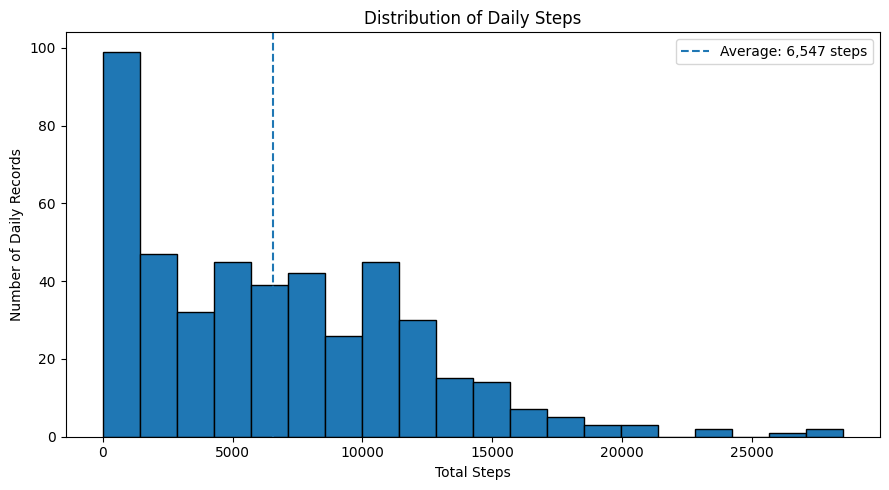

Chart saved successfully!


In [45]:
#Creating the first chart
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(daily_activity["TotalSteps"], bins=20, edgecolor="black")

plt.title("Distribution of Daily Steps")
plt.xlabel("Total Steps")
plt.ylabel("Number of Daily Records")
plt.axvline(
    daily_activity["TotalSteps"].mean(),
    linestyle="--",
    label="Average: 6,547 steps"
)

plt.legend()
plt.tight_layout()
plt.savefig("bellabeat_daily_steps_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully!")

### Finding 1: Distribution of Daily Steps

The analysis examined 457 daily activity records from 35 unique users. The average daily step count was approximately 6,547 steps, while the median was 5,986 steps.

The distribution shows variation in daily step counts, suggesting that users differed in their activity levels. Bellabeat could explore personalized step goals and progress updates to help users build activity habits suited to their individual routines.

**Limitation:** The dataset covers a limited period and a relatively small group of users. The results may not represent all Bellabeat customers or the broader population.

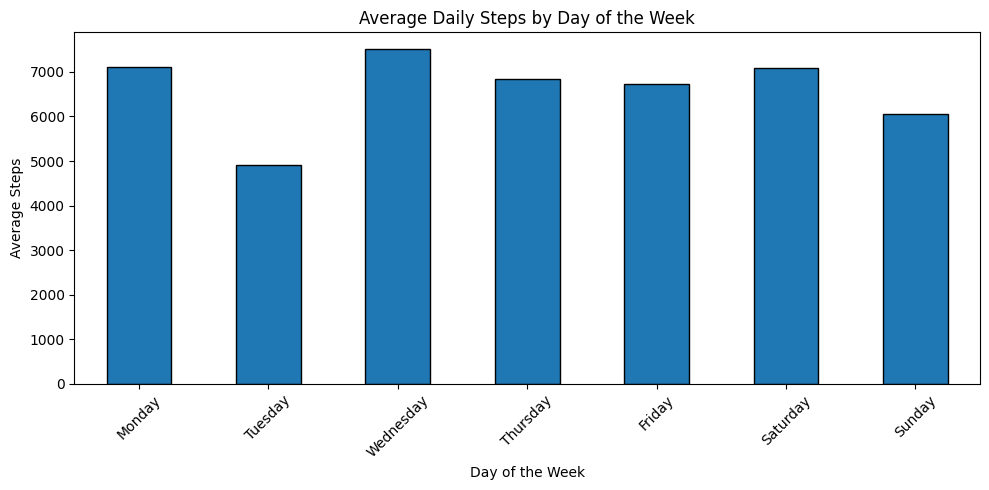

Chart saved successfully!


In [46]:
#Creating the second chart
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

weekday_steps.plot(kind="bar", edgecolor="black")

plt.title("Average Daily Steps by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Steps")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "bellabeat_steps_by_weekday.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")

### Finding 2: Average Steps by Day of the Week

The analysis showed differences in average daily steps across the week. Wednesday had the highest average at approximately 7,511 steps, while Tuesday had the lowest average at approximately 4,915 steps. Average steps were approximately 7,090 on Saturday and 6,058 on Sunday.

These patterns suggest that activity levels may vary depending on the day of the week. Bellabeat could explore offering flexible activity reminders, weekday challenges, and personalized weekend goals to encourage users to maintain consistent activity habits.

**Limitation:** These results describe the observed daily records, not necessarily the behavior of every individual user. The data does not establish why activity levels differed by day.

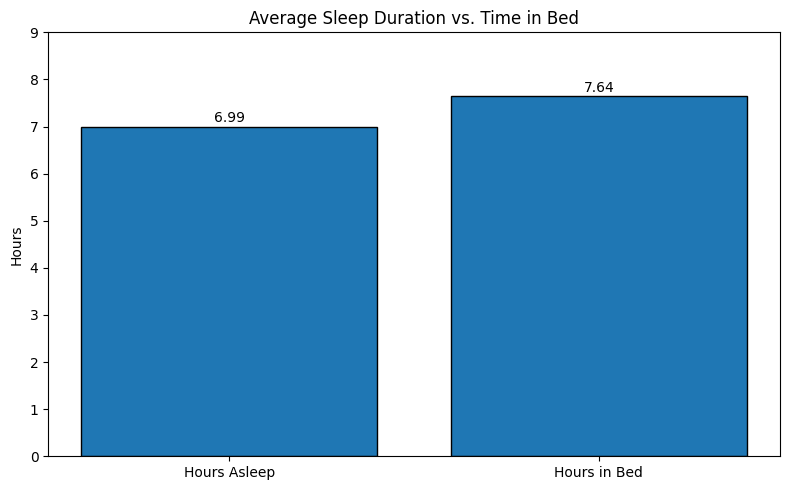

Chart saved successfully!


In [47]:
#creating the third chart
import matplotlib.pyplot as plt

sleep_averages = [
    sleep_day["HoursAsleep"].mean(),
    sleep_day["HoursInBed"].mean()
]

labels = ["Hours Asleep", "Hours in Bed"]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, sleep_averages, edgecolor="black")

plt.title("Average Sleep Duration vs. Time in Bed")
plt.ylabel("Hours")
plt.ylim(0, 9)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{bar.get_height():.2f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    "bellabeat_sleep_vs_time_in_bed.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Chart saved successfully!")

### Finding 3: Sleep Patterns

The analysis examined 410 sleep records after removing three duplicate records. Participants slept for an average of approximately 6.99 hours per recorded night and spent approximately 7.64 hours in bed. The difference between time in bed and time asleep was approximately 40 minutes on average.

These results suggest that tracking sleep duration and the time spent in bed may help users better understand their sleep routines. Bellabeat could explore presenting sleep summaries and personalized insights through its app to encourage users to reflect on their sleep habits.

**Limitation:** The sleep dataset included 24 unique users and covered a different date range from most of the daily activity data. Therefore, the available matched records were insufficient to draw reliable conclusions about the relationship between steps and sleep. The results also do not establish the quality of participants' sleep.

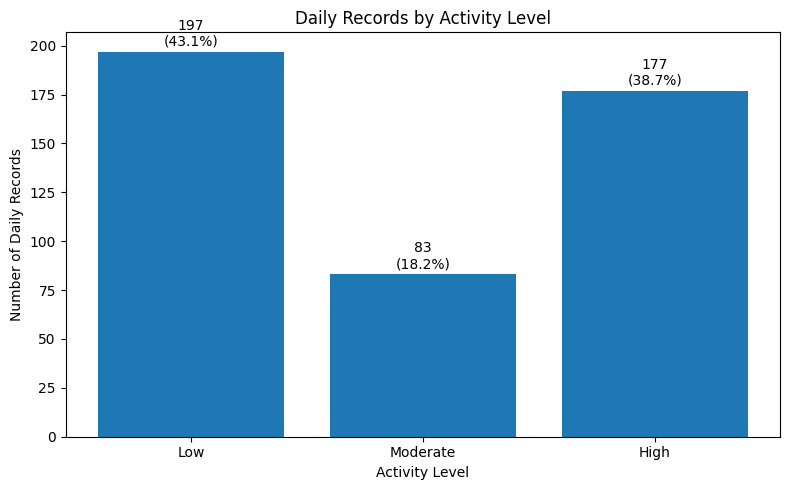

In [48]:

# Visualize daily records by activity level
import matplotlib.pyplot as plt

activity_order = ["Low", "Moderate", "High"]
activity_counts_ordered = (
    daily_activity["ActivityLevel"]
    .value_counts()
    .reindex(activity_order)
)

plt.figure(figsize=(8, 5))
bars = plt.bar(
    activity_counts_ordered.index,
    activity_counts_ordered.values
)

plt.title("Daily Records by Activity Level")
plt.xlabel("Activity Level")
plt.ylabel("Number of Daily Records")

for bar, count in zip(bars, activity_counts_ordered.values):
    percentage = count / len(daily_activity) * 100
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 3,
        f"{count}\n({percentage:.1f}%)",
        ha="center"
    )

plt.tight_layout()
plt.savefig("bellabeat_activity_levels.png", dpi=300)
plt.show()


### Finding 4: Daily Activity Levels

The analysis categorized 457 daily activity records into three exploratory step-count groups:

- **Low activity:** 197 records (43.1%), fewer than 5,000 steps.
- **Moderate activity:** 83 records (18.2%), between 5,000 and 7,499 steps.
- **High activity:** 177 records (38.7%), 7,500 steps or more.

Low-activity records represented the largest share of the dataset. This suggests an opportunity for Bellabeat to explore gentle activity reminders, personalized daily goals, and progress tracking through its app.

**Limitation:** These categories are exploratory rather than clinical classifications. Some low-step records may reflect rest days or incomplete tracker use, so they should not automatically be interpreted as inactivity.


##Overall Analysis Summary

The analysis explored daily activity and sleep patterns using Fitbit tracker data from March to May 2016. The daily activity dataset contained 457 records from 35 unique users, while the cleaned sleep dataset contained 410 records from 24 unique users.

Key findings include:

1. **Daily steps:** Participants averaged approximately 6,547 steps per recorded day, with considerable variation in activity levels.
2. **Weekly patterns:** Wednesday had the highest average step count, while Tuesday had the lowest.
3. **Sleep patterns:** Participants slept for an average of approximately 6.99 hours per recorded night and spent approximately 7.64 hours in bed.
4. **Activity categories:** Low-activity records represented 43.1% of daily records, while high-activity records represented 38.7%.

Overall, the results suggest opportunities for Bellabeat to explore personalized activity goals, timely movement reminders, and sleep-tracking summaries through its app.

**Data limitations:** The dataset is relatively small and comes from 2016. The activity and sleep datasets cover different date ranges, preventing a reliable analysis of the relationship between daily steps and sleep. The findings describe this dataset and should not be assumed to represent all Bellabeat customers.

## Marketing Recommendations for Bellabeat

Based on the observed Fitbit activity and sleep patterns, the following recommendations could help Bellabeat explore ways to engage users through its app.

### 1. Introduce Personalized Daily Activity Goals
Because 43.1% of daily records fell below 5,000 steps, Bellabeat could offer adjustable step goals based on users' current activity levels and progress. Gentle reminders may encourage users to move more throughout the day.

### 2. Explore Day-Specific Activity Challenges
Tuesday had the lowest average step count, while Wednesday had the highest. Bellabeat could test a Tuesday movement challenge, weekday reminders, or flexible weekend goals to encourage more consistent activity.

### 3. Provide Clear Sleep Summaries
The average recorded sleep duration was approximately 6.99 hours. Bellabeat could display sleep-duration trends and time-in-bed summaries so users can reflect on their routines. These insights should be presented as wellness information, not as a diagnosis or assessment of sleep quality.

### 4. Test and Measure Marketing Campaigns
Bellabeat could test personalized notifications and activity challenges with a small group of app users. The company could compare engagement, goal completion, and retention between users who receive the features and those who do not.



## Limitations

- **Small sample:** The analysis uses 457 daily activity records from 35 participants and 410 cleaned sleep records from 24 participants. These results may not represent all Bellabeat customers.
- **Limited time period:** The activity dataset covers March 12 to April 9, 2016, so it may not reflect long-term habits or seasonal changes.
- **Missing or incomplete tracking:** Some daily records show zero steps. These may represent rest days or incomplete device use.
- **Limited activity and sleep overlap:** Only 12 records matched by participant and date, so this analysis cannot establish a reliable relationship between daily steps and sleep.
- **Historical data:** The Fitbit data is from 2016 and represents Fitbit users, not necessarily Bellabeat customers. The findings should be treated as exploratory insights, not proof of current customer behavior.

### Conclusion
The data suggests opportunities to explore personalized activity tracking, day-specific engagement, and sleep summaries. Bellabeat should test these ideas with its own users before making broad marketing decisions, because this historical Fitbit dataset is small and may not represent Bellabeat customers.